In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# 14장 합성곱 신경망을 사용한 컴퓨터 비전

## 14.2 합성곱 층

### 14.2.3 케라스로 합성곱 층 구현하기

In [2]:
from sklearn.datasets import load_sample_images

images = load_sample_images()['images']
images = tf.keras.layers.CenterCrop(height=70, width=120)(images)
images = tf.keras.layers.Rescaling(scale=1/255)(images)

In [3]:
images.shape

TensorShape([2, 70, 120, 3])

In [4]:
tf.random.set_seed(42)

conv_layer = tf.keras.layers.Conv2D(filters=32, kernel_size=7)
fmaps = conv_layer(images)

fmaps.shape

TensorShape([2, 64, 114, 32])

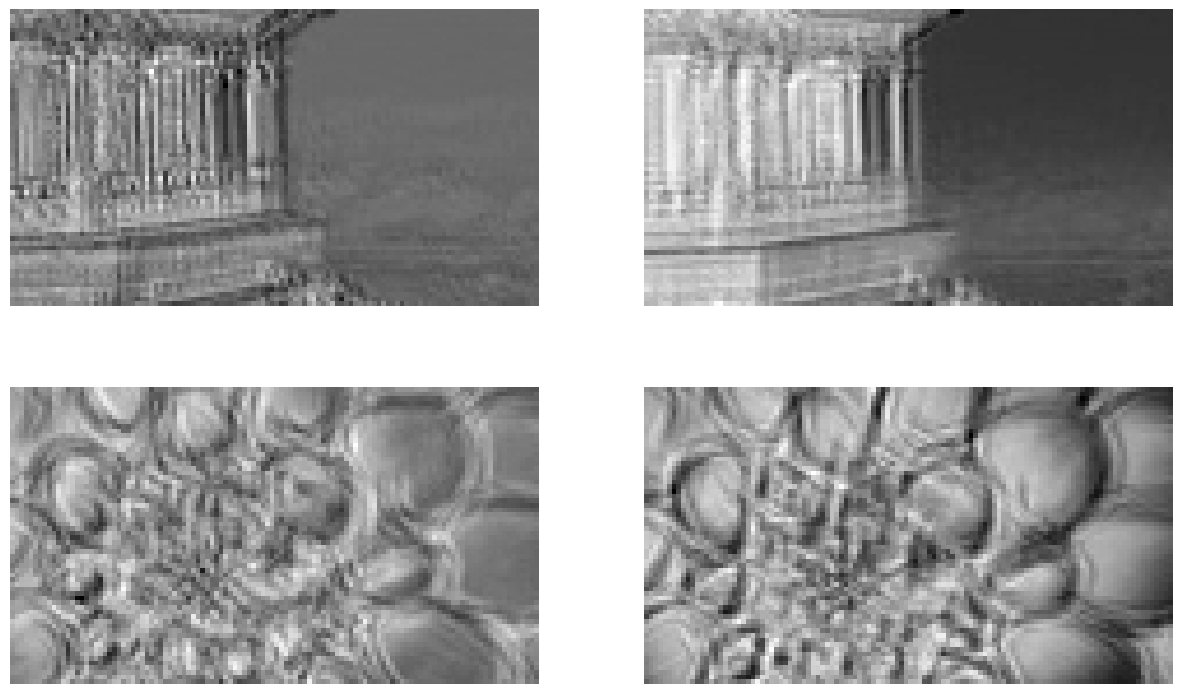

In [5]:
plt.figure(figsize=(15, 9))
for image_idx in (0, 1):
    for fmap_idx in (0, 1):
        plt.subplot(2, 2, image_idx * 2 + fmap_idx + 1)
        plt.imshow(fmaps[image_idx, :, :, fmap_idx], cmap='gray')
        plt.axis('off')
plt.show()

In [6]:
conv_layer = tf.keras.layers.Conv2D(filters=32, kernel_size=7, padding='same')
fmaps = conv_layer(images)

fmaps.shape

TensorShape([2, 70, 120, 32])

In [7]:
kernels, biases = conv_layer.get_weights()
kernels.shape

(7, 7, 3, 32)

In [8]:
biases.shape

(32,)

## 14.4 케라스로 풀링 층 구현하기

In [9]:
max_pool = tf.keras.layers.MaxPool2D(pool_size=2)

In [10]:
class DepthPool(tf.keras.layers.Layer):
    def __init__(self, pool_size=2, **kwargs):
        super.__init__(**kwargs)
        self.pool_size = pool_size

    def call(self, inputs):
        shape = tf.shape(inputs)
        groups = shape[-1] // self.pool_size
        new_shape = tf.concat([shape[:-1], [groups, self.pool_size]], axis=0)
        return tf.reduce_max(tf.reshape(inputs, new_shape), axis=-1)

In [11]:
global_avg_pool = tf.keras.layers.GlobalAvgPool2D()

In [12]:
global_avg_pool = tf.keras.layers.Lambda(
    lambda X: tf.reduce_mean(X, axis=[1, 2])
)

In [13]:
global_avg_pool(images)

<tf.Tensor: shape=(2, 3), dtype=float32, numpy=
array([[0.64338624, 0.5971759 , 0.5824972 ],
       [0.76306933, 0.2601113 , 0.10849128]], dtype=float32)>

## 14.5 CNN 구조

In [14]:
mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = mnist
X_train_full = np.expand_dims(X_train_full, axis=-1).astype(np.float32) / 255
X_test = np.expand_dims(X_test.astype(np.float32), axis=-1) / 255
X_train, X_valid = X_train_full[:-5000], X_train_full[-5000:]
y_train, y_valid = y_train_full[:-5000], y_train_full[-5000:]

In [15]:
from functools import partial

tf.random.set_seed(42)

DefaultConv2D = partial(tf.keras.layers.Conv2D, kernel_size=3, padding='same',
                        activation='relu', kernel_initializer='he_normal')

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    DefaultConv2D(filters=64, kernel_size=7),
    tf.keras.layers.MaxPool2D(),
    DefaultConv2D(filters=128),
    DefaultConv2D(filters=128),
    tf.keras.layers.MaxPool2D(),
    DefaultConv2D(filters=256),
    DefaultConv2D(filters=256),
    tf.keras.layers.MaxPool2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(64, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │         3,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 7, 7, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,413,834 (5.39 MB)

 Trainable params: 1,413,834 (5.39 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(loss='sparse_categorical_crossentropy', optimizer='nadam',
              metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=10, validation_data=(X_valid, y_valid))

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 144s 83ms/step - accuracy: 0.7408 - loss: 0.7338 - val_accuracy: 0.8538 - val_loss: 0.4146
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 114s 66ms/step - accuracy: 0.8558 - loss: 0.4280 - val_accuracy: 0.8874 - val_loss: 0.3086
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 111s 65ms/step - accuracy: 0.8767 - loss: 0.3641 - val_accuracy: 0.8946 - val_loss: 0.2887
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 112s 65ms/step - accuracy: 0.8911 - loss: 0.3191 - val_accuracy: 0.9020 - val_loss: 0.2762
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 112s 65ms/step - accuracy: 0.9005 - loss: 0.2901 - val_accuracy: 0.9060 - val_loss: 0.2633
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 139s 81ms/step - accuracy: 0.9061 - loss: 0.2726 - val_accuracy: 0.9098 - val_loss: 0.2549
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 138s 80ms/step - accuracy: 0.9149 - loss: 0.2458 - val_accuracy: 0.9050 - val_loss: 0.2646
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 131s 76ms/step - accuracy: 

In [18]:
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9070 - loss: 0.3134


[0.31342682242393494, 0.9070000052452087]

## 14.6 케라스로 ResNet-34 CNN 구현하기

In [19]:
DefaultConv2D = partial(tf.keras.layers.Conv2D, kernel_size=3, strides=1,
                        padding='same', kernel_initializer='he_normal',
                        use_bias=False)

class ResidualUnit(tf.keras.layers.Layer):
    def __init__(self, filters, strides=1, activation='relu', **kwargs):
        super().__init__(**kwargs)
        self.activation = tf.keras.activations.get(activation)
        self.main_layers = [
            DefaultConv2D(filters, strides=strides),
            tf.keras.layers.BatchNormalization(),
            self.activation,
            DefaultConv2D(filters),
            tf.keras.layers.BatchNormalization()
        ]
        self.skip_layers = []
        if strides > 1:
            self.skip_layers = [
                DefaultConv2D(filters, kernel_size=1, strides=strides),
                tf.keras.layers.BatchNormalization()
            ]

    def call(self, inputs):
        Z = inputs
        for layer in self.main_layers:
            Z = layer(Z)
        
        skip_Z = inputs
        for layer in self.skip_layers:
            skip_Z = layer(skip_Z)

        return self.activation(Z + skip_Z)

In [20]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    DefaultConv2D(64, kernel_size=7, strides=2),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPool2D(pool_size=3, strides=2, padding='same'),
])

prev_filters = 64
for filters in [64]*3 + [128]*4 + [256]*6 + [512]*3:
    strides = 1 if filters == prev_filters else 2
    model.add(ResidualUnit(filters, strides=strides))
    prev_filters = filters

model.add(tf.keras.layers.GlobalAvgPool2D())
model.add(tf.keras.layers.Flatten()),
model.add(tf.keras.layers.Dense(10, activation='softmax'))

In [21]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 112, 112, 64)   │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit (ResidualUnit)    │ (None, 56, 56, 64)     │        74,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_1 (ResidualUnit)  │ (None, 56, 56, 64)     │        74,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_2 (ResidualUnit)  │ (None, 56, 56, 64)     │        74,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_3 (ResidualUnit)  │ (None, 28, 28, 128)    │       230,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_4 (ResidualUnit)  │ (None, 28, 28, 128)    │       295,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_5 (ResidualUnit)  │ (None, 28, 28, 128)    │       295,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_6 (ResidualUnit)  │ (None, 28, 28, 128)    │       295,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_7 (ResidualUnit)  │ (None, 14, 14, 256)    │       920,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_8 (ResidualUnit)  │ (None, 14, 14, 256)    │     1,181,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_9 (ResidualUnit)  │ (None, 14, 14, 256)    │     1,181,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_10 (ResidualUnit) │ (None, 14, 14, 256)    │     1,181,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_11 (ResidualUnit) │ (None, 14, 14, 256)    │     1,181,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_12 (ResidualUnit) │ (None, 14, 14, 256)    │     1,181,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_13 (ResidualUnit) │ (None, 7, 7, 512)      │     3,676,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_14 (ResidualUnit) │ (None, 7, 7, 512)      │     4,722,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_15 (ResidualUnit) │ (None, 7, 7, 512)      │     4,722,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,306,826 (81.28 MB)

 Trainable params: 21,289,802 (81.21 MB)

 Non-trainable params: 17,024 (66.50 KB)

## 14.7 케라스의 사전 훈렬 모델 사용하기

In [22]:
model = tf.keras.applications.resnet50.ResNet50(weights='imagenet')

In [23]:
images = load_sample_images()['images']
images_resized = tf.keras.layers.Resizing(height=224, width=224,
                                          crop_to_aspect_ratio=True)(images)

In [24]:
Y_proba = model.predict(images_resized)
Y_proba.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 702ms/step


(2, 1000)

In [25]:
top_K = tf.keras.applications.resnet50.decode_predictions(Y_proba, top=3)
for image_index in range(len(images)):
    print(f'Image #{image_index}')
    for class_id, name, y_proba in top_K[image_index]:
        print(f' {class_id} - {name:15s} {y_proba:.2%}')

Image #0
 n03877845 - palace          73.39%
 n02966193 - carousel        9.42%
 n02825657 - bell_cote       5.11%
Image #1
 n04522168 - vase            55.74%
 n11939491 - daisy           12.50%
 n02206856 - bee             10.44%


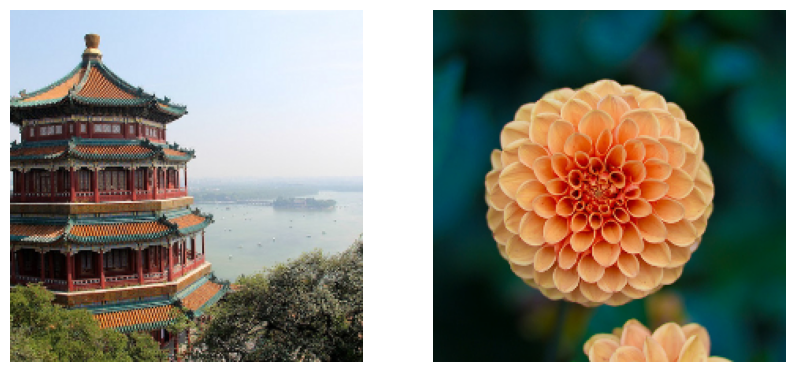

In [26]:
plt.figure(figsize=(10, 6))
for idx in (0, 1):
    plt.subplot(1, 2, idx + 1)
    plt.imshow(images_resized[idx])
    plt.axis('off')
plt.show()

## 14.8 사전 훈련된 모델을 사용한 전이 학습

In [27]:
import tensorflow_datasets as tfds

dataset, info = tfds.load('tf_flowers', as_supervised=True, with_info=True)

In [28]:
dataset_size = info.splits['train'].num_examples
dataset_size

3670

In [29]:
class_names = info.features['label'].names
class_names

['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']

In [30]:
n_classes = info.features['label'].num_classes
n_classes

5

In [31]:
test_set_raw, valid_set_raw, train_set_raw = tfds.load('tf_flowers',
    split=['train[:10%]', 'train[10%:25%]', 'train[25%:]'], as_supervised=True)

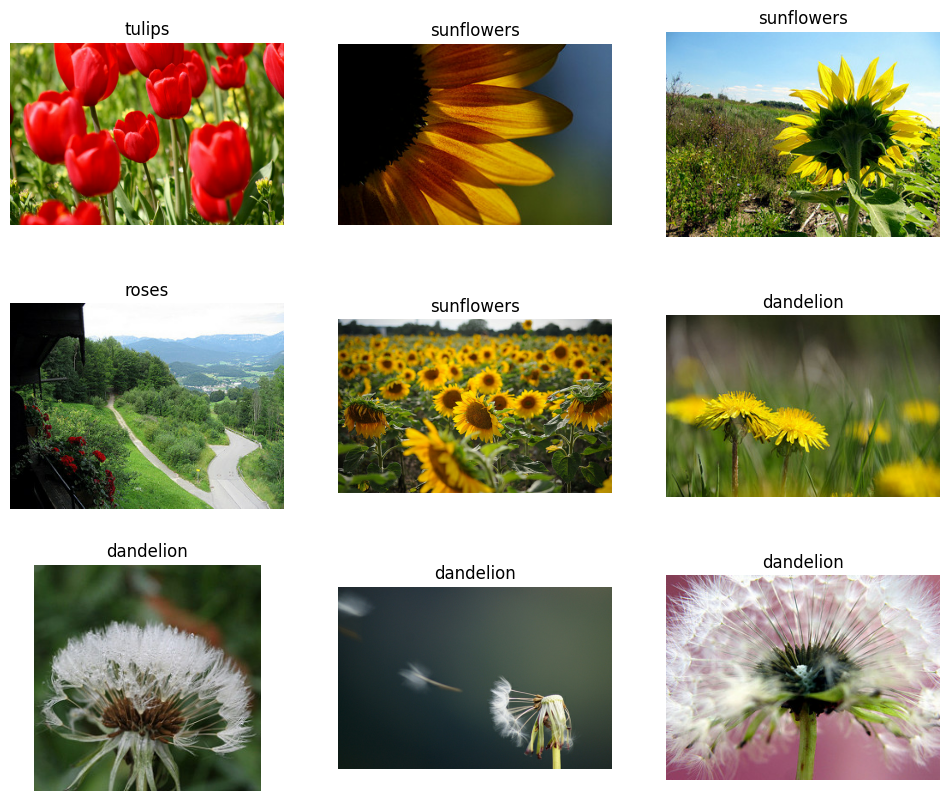

In [32]:
plt.figure(figsize=(12, 10))
for idx, (image, label) in enumerate(test_set_raw.take(9)):
    plt.subplot(3, 3, idx + 1)
    plt.imshow(image)
    plt.title(class_names[label])
    plt.axis('off')
plt.show()

In [33]:
batch_size = 32
preprocess = tf.keras.models.Sequential([
    tf.keras.layers.Resizing(height=224, width=224, crop_to_aspect_ratio=True),
    tf.keras.layers.Lambda(tf.keras.applications.xception.preprocess_input)
])

train_set = train_set_raw.map(lambda X, y: (preprocess(X), y))
train_set = train_set.shuffle(1000, seed=42).batch(batch_size).prefetch(1)
valid_set = valid_set_raw.map(lambda X, y: (preprocess(X), y)).batch(batch_size)
test_set = test_set_raw.map(lambda X, y: (preprocess(X), y)).batch(batch_size)

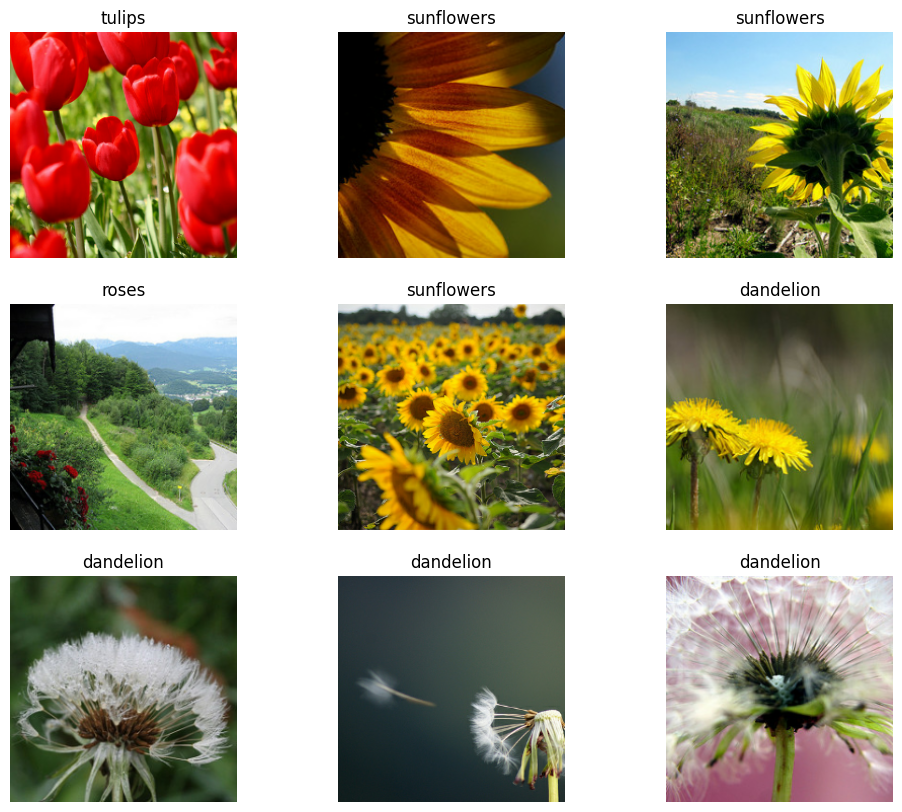

In [34]:
plt.figure(figsize=(12, 10))
for X_batch, y_batch in test_set.take(1):
    for idx in range(9):
        plt.subplot(3, 3, idx + 1)
        plt.imshow((X_batch[idx] + 1) / 2)
        plt.title(class_names[y_batch[idx]])
        plt.axis('off')
plt.show()

In [35]:
data_augmentation = tf.keras.models.Sequential([
    tf.keras.layers.RandomFlip(mode='horizontal', seed=42),
    tf.keras.layers.RandomRotation(factor=0.05, seed=42),
    tf.keras.layers.RandomContrast(factor=0.2, seed=42)
])

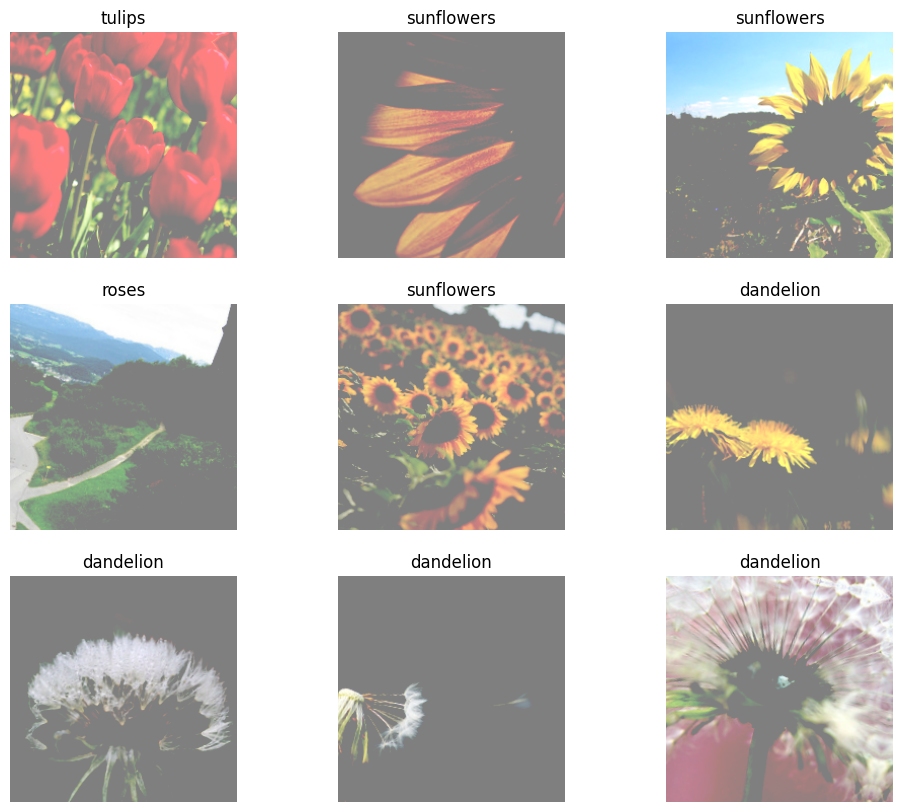

In [36]:
plt.figure(figsize=(12, 10))
for X_batch, y_batch in test_set.take(1):
    X_batch_augmented = data_augmentation(X_batch)
    for idx in range(9):
        plt.subplot(3, 3, idx + 1)
        plt.imshow(np.clip((X_batch_augmented[idx] + 1) / 2, 0, 1))
        plt.title(class_names[y_batch[idx]])
        plt.axis('off')
plt.show()

In [37]:
tf.random.set_seed(42)

base_model = tf.keras.applications.xception.Xception(weights='imagenet', include_top=False)
avg = tf.keras.layers.GlobalAveragePooling2D()(base_model.output)
output = tf.keras.layers.Dense(n_classes, activation='softmax')(avg)
model = tf.keras.Model(inputs=base_model.input, outputs=output)

In [38]:
for layer in base_model.layers:
    layer.trainable = False

In [39]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.1, momentum=0.9)
model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer,
              metrics=['accuracy'])
history = model.fit(train_set, epochs=3, validation_data=valid_set)

Epoch 1/3
86/86 ━━━━━━━━━━━━━━━━━━━━ 119s 1s/step - accuracy: 0.8027 - loss: 0.7799 - val_accuracy: 0.8621 - val_loss: 0.6914
Epoch 2/3
86/86 ━━━━━━━━━━━━━━━━━━━━ 127s 1s/step - accuracy: 0.9055 - loss: 0.3666 - val_accuracy: 0.8367 - val_loss: 0.7635
Epoch 3/3
86/86 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.9440 - loss: 0.1914 - val_accuracy: 0.8512 - val_loss: 0.6551


In [40]:
for layer in base_model.layers[56:]:
    layer.trainable = True

In [41]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer,
              metrics=['accuracy'])
history = model.fit(train_set, epochs=10, validation_data=valid_set)

Epoch 1/10


86/86 ━━━━━━━━━━━━━━━━━━━━ 309s 4s/step - accuracy: 0.9044 - loss: 0.2903 - val_accuracy: 0.8548 - val_loss: 0.6833
Epoch 2/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 288s 3s/step - accuracy: 0.9815 - loss: 0.0616 - val_accuracy: 0.9074 - val_loss: 0.3560
Epoch 3/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 297s 3s/step - accuracy: 0.9942 - loss: 0.0204 - val_accuracy: 0.8929 - val_loss: 0.3843
Epoch 4/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 309s 4s/step - accuracy: 0.9945 - loss: 0.0204 - val_accuracy: 0.9165 - val_loss: 0.3158
Epoch 5/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 303s 4s/step - accuracy: 0.9978 - loss: 0.0070 - val_accuracy: 0.9201 - val_loss: 0.2920
Epoch 6/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 291s 3s/step - accuracy: 0.9971 - loss: 0.0060 - val_accuracy: 0.9256 - val_loss: 0.3141
Epoch 7/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 256s 3s/step - accuracy: 0.9985 - loss: 0.0037 - val_accuracy: 0.9256 - val_loss: 0.3263
Epoch 8/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 276s 3s/step - accuracy: 0.9993 - loss: 0.0025 - val_accuracy: 0.9292 - val_loss: 0.

## 14.9 분류와 위치 추정

In [42]:
tf.random.set_seed(42)

base_model = tf.keras.applications.xception.Xception(weights='imagenet', include_top=False)
avg = tf.keras.layers.GlobalAveragePooling2D()(base_model.output)
class_output = tf.keras.layers.Dense(n_classes, activation='softmax')(avg)
loc_output = tf.keras.layers.Dense(4)(avg)
model = tf.keras.Model(inputs=base_model.input, outputs=[class_output, loc_output])

optimizer = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
model.compile(loss=['sparse_categorical_crossentropy', 'mse'], loss_weights=[0.8, 0.2],
              optimizer=optimizer, metrics=['accuracy', 'mse'])

In [43]:
def add_random_bounding_boxes(images, labels):
    fake_bboxes = tf.random.uniform([tf.shape(images)[0], 4])
    return images, (labels, fake_bboxes)

fake_train_set = train_set.take(5).repeat(2).map(add_random_bounding_boxes)
history = model.fit(fake_train_set, epochs=2)

Epoch 1/2
10/10 ━━━━━━━━━━━━━━━━━━━━ 60s 5s/step - dense_5_accuracy: 0.3625 - dense_5_loss: 1.4783 - dense_6_loss: 0.2545 - dense_6_mse: 0.2545 - loss: 1.2336
Epoch 2/2
10/10 ━━━━━━━━━━━━━━━━━━━━ 57s 6s/step - dense_5_accuracy: 0.6719 - dense_5_loss: 1.0425 - dense_6_loss: 0.2007 - dense_6_mse: 0.2007 - loss: 0.8742


## 연습문제

### ⑩

In [44]:
mnist = tf.keras.datasets.mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = mnist
X_train_full = X_train_full / 255.
X_test = X_test / 255.
X_train, X_valid = X_train_full[:-5000], X_train_full[-5000:]
y_train, y_valid = y_train_full[:-5000], y_train_full[-5000:]

X_train = np.expand_dims(X_train, axis=-1)
X_valid = np.expand_dims(X_valid, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

In [45]:
X_train.shape

(55000, 28, 28, 1)

In [46]:
tf.keras.utils.set_random_seed(42)

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, kernel_size=3, padding='same',
                           activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Conv2D(64, kernel_size=3, padding='same',
                           activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.MaxPool2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(128, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(10, activation='softmax')
])
model.compile(loss='sparse_categorical_crossentropy', optimizer='nadam',
              metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=10, validation_data=(X_valid, y_valid))

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 45s 26ms/step - accuracy: 0.9367 - loss: 0.2115 - val_accuracy: 0.9886 - val_loss: 0.0442
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 46s 27ms/step - accuracy: 0.9734 - loss: 0.0896 - val_accuracy: 0.9900 - val_loss: 0.0409
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 41s 24ms/step - accuracy: 0.9789 - loss: 0.0692 - val_accuracy: 0.9922 - val_loss: 0.0362
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 44s 25ms/step - accuracy: 0.9830 - loss: 0.0564 - val_accuracy: 0.9900 - val_loss: 0.0397
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 39s 23ms/step - accuracy: 0.9858 - loss: 0.0448 - val_accuracy: 0.9916 - val_loss: 0.0383
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 39s 23ms/step - accuracy: 0.9881 - loss: 0.0384 - val_accuracy: 0.9916 - val_loss: 0.0381
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 39s 22ms/step - accuracy: 0.9885 - loss: 0.0357 - val_accuracy: 0.9914 - val_loss: 0.0383
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 38s 22ms/step - accuracy: 0.9898 -

In [47]:
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9901 - loss: 0.0342


[0.03423063084483147, 0.9901000261306763]